In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
import sys
import yaml
from pathlib import Path
from tqdm.auto import tqdm
from joblib import Parallel, delayed
from scipy.spatial.distance import hamming

# make figures paper quality
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# matplotlib.rcParams['font.family'] = 'Arial'

import warnings
warnings.filterwarnings("ignore")

/home/peidli/miniconda3/envs/sc_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)

seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']

path = Path(config['TEMPDIR']) / 'pooled_screen_1/'
cell_line_dict={
    '01': 'H1975',
    '02': 'H1299',
    '03': 'A549'
}

# Prepare the Data

In [3]:
# Define data
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
# df = pd.read_csv('/Users/peidli/work/data/SYMPHONY/pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

In [4]:
# Normalize to NT depth
norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)
ndf = df.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

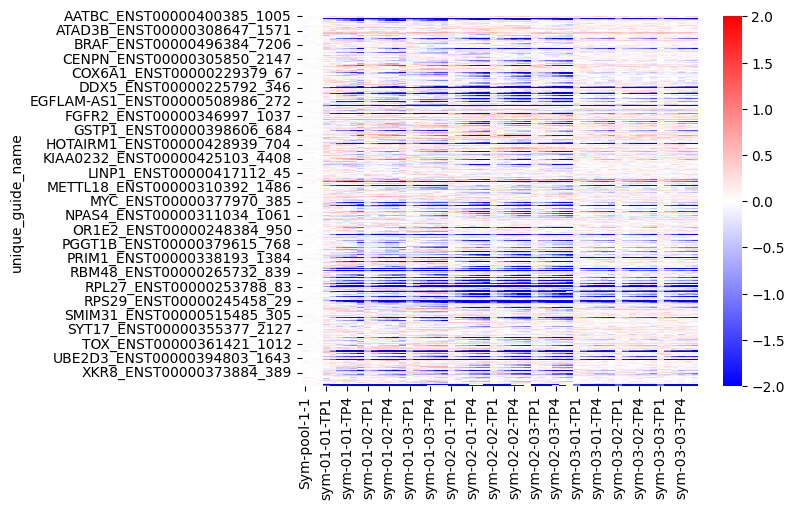

In [5]:
# sanity check
sns.heatmap(l2fc, cmap='bwr', center=0, vmin=-2, vmax=2); 

In [6]:
# annotate
tab = l2fc.iloc[:, 3:].T
tab['time'] = [x.split('-')[-1] for x in tab.index]
tab['replicate'] = [x.split('-')[2] for x in tab.index]
tab['cell_line'] = [x.split('-')[1] for x in tab.index]

In [7]:
tab.head()

unique_guide_name,AATBC_ENST00000400385_1005,AATBC_ENST00000400385_1562,AATBC_ENST00000400385_1938,AATBC_ENST00000400385_2713,AATBC_ENST00000400385_28,AATBC_ENST00000400385_3041,AATBC_ENST00000400385_3400,AATBC_ENST00000400385_3822,AATBC_ENST00000400385_4379,AATBC_ENST00000400385_827,...,RPL27_ENST00000253788_118,RPL8_ENST00000262584_578,RPS16_ENST00000251453_280,RPS16_ENST00000251453_300,RPS5_ENST00000196551_431,RPS5_ENST00000196551_574,RPS5_ENST00000196551_68,time,replicate,cell_line
sym-01-01-TP1,0.146398,0.162346,0.238029,-0.056598,-0.094600,0.166914,0.379760,-0.244079,0.090783,0.207001,...,-0.386280,-0.311815,-0.629568,0.489420,0.031667,0.192628,-3.695664,TP1,01,01
sym-01-01-TP2,0.093134,0.304380,0.313556,-0.109057,0.211260,0.160999,0.304467,-0.332941,0.061524,0.469882,...,-0.779336,-1.882934,-2.810892,-0.189655,-0.482426,-0.141234,-3.943473,TP2,01,01
sym-01-01-TP3,0.171927,0.203205,0.299697,-0.208690,0.055166,0.237149,0.196762,-0.178278,0.246684,0.324230,...,-1.286402,-3.043400,-4.717305,-0.845756,-0.938696,-0.277372,-4.567844,TP3,01,01
sym-01-01-TP4,0.146828,0.178063,0.299847,-0.293236,0.137690,0.223240,0.018390,-0.125729,0.282916,0.308191,...,-1.575086,-3.179436,-6.377046,-1.326081,-1.211748,-0.596584,-4.924297,TP4,01,01
sym-01-01-TP5,0.263337,0.159170,0.098082,-0.352253,0.101403,0.163011,0.093006,0.001447,0.109042,0.213493,...,-2.171101,-2.907006,NaN,-1.725376,-1.526994,-0.612919,-4.651416,TP5,01,01


In [8]:
# mean over replicates
mtab = tab.fillna(0).drop('replicate', axis=1).groupby(['cell_line', 'time']).mean()  

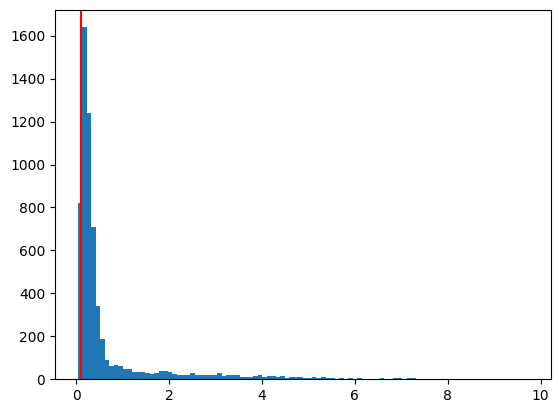

In [9]:
# remove guides with too low signal
eps = 0.1
pl.hist(mtab.loc['01'].abs().max(), bins=100)
pl.axvline(eps, color='r')
pl.show()

In [10]:
# Do analysis on each line separately (here: 01)
from sklearn.preprocessing import MinMaxScaler
data = mtab.loc['01']
data = data.loc[:, data.abs().max() > eps]
scaler = MinMaxScaler()
Y = scaler.fit_transform(data)

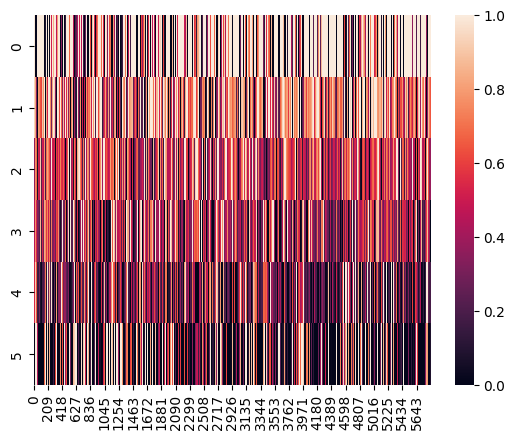

In [11]:
# sanity check
sns.heatmap(Y)
pl.show()

# Clustering

https://www.kaggle.com/code/izzettunc/introduction-to-time-series-clustering

In [12]:
# !pip install tslearn minisom --quiet

In [13]:
from tslearn.barycenters import dtw_barycenter_averaging as dba
from tslearn.clustering import TimeSeriesKMeans

In [14]:
# K = np.ceil(np.sqrt(Y.shape[1]/7)).astype(int)
K = 5  # instead of a whooping 30
# A good rule of thumb is choosing k as the square root of the number of points in the training data set in kNN

km = TimeSeriesKMeans(n_clusters=K, metric="dtw")

In [15]:
# Fit K-Means and get labels
labels = km.fit_predict(Y.T)
res = pd.DataFrame(Y.T, index = data.columns)
res['label'] = labels

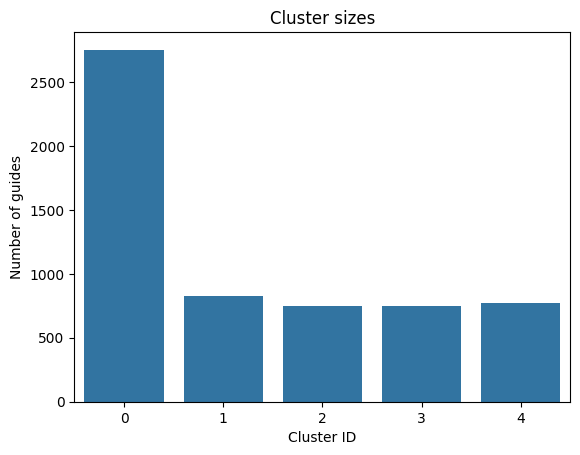

In [16]:
cts = np.unique(labels, return_counts=True)
# plot as bars
sns.barplot(x=cts[0], y=cts[1])
pl.title('Cluster sizes')
pl.xlabel('Cluster ID')
pl.ylabel('Number of guides')
pl.show()

In [17]:
# Calculate representative time series for each cluster
reps = res.groupby('label').mean()
reps_ = {label: np.ravel(dba(res[res['label']==label].drop('label', axis=1).values)) for label in tqdm(np.unique(labels))}
reps_ = pd.DataFrame(reps_).T

100%|██████████| 5/5 [00:22<00:00,  4.48s/it]


In [18]:
# distance from reps to quantify goodness of fit
from tslearn.metrics import dtw
scores = pd.DataFrame(index=res.index, columns=['label', 'dtw'])
for label in tqdm(reps_.index):
    mask = res['label']==label
    data = res[mask].drop('label', axis=1).values
    scores.loc[mask, 'dtw'] = [dtw(reps_.loc[label], x) for x in data]
    scores.loc[mask, 'label'] = label
scores['score'] = - np.log(np.array(scores['dtw'].fillna(0).values, dtype=float))

100%|██████████| 5/5 [00:05<00:00,  1.01s/it]


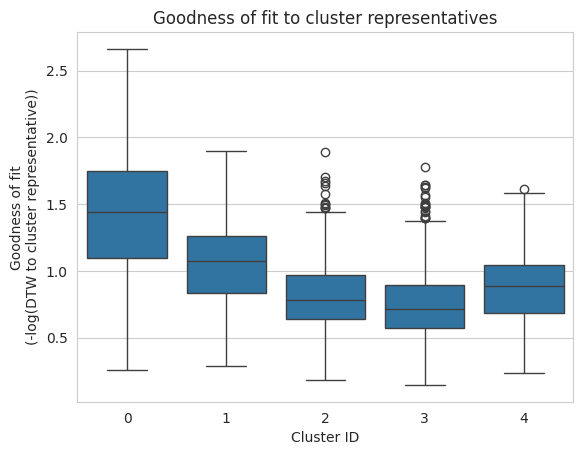

In [19]:
with sns.axes_style('whitegrid'):
    sns.boxplot(x='label', y='score', data=scores)
pl.ylabel('Goodness of fit\n(-log(DTW to cluster representative))')
pl.xlabel('Cluster ID')
pl.title('Goodness of fit to cluster representatives')
pl.show()

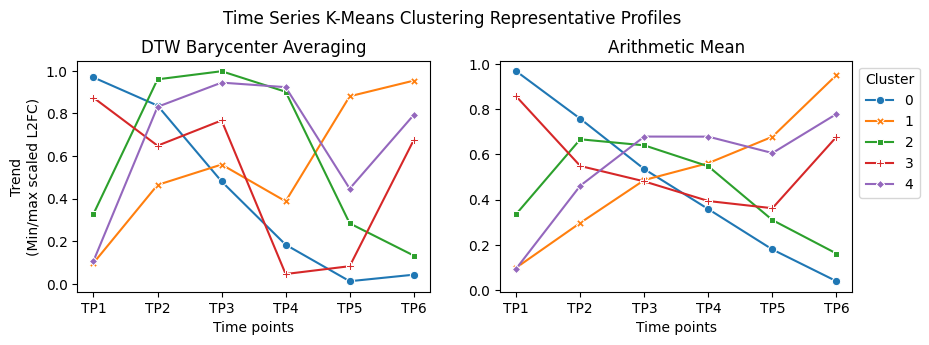

In [20]:
fig, axs = pl.subplots(1, 2, figsize=(10, 3))
ax = axs[0]
sns.lineplot(data=reps_.T, dashes=False, markers=True, ax=ax)
ax.legend_.remove()
ax.set_title('DTW Barycenter Averaging')
ax.set_ylabel('Trend\n(Min/max scaled L2FC)')

ax = axs[1]
sns.lineplot(data=reps.T, dashes=False, markers=True, ax=ax)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), title='Cluster')
ax.set_title('Arithmetic Mean')

for ax in axs:
    ax.set_xlabel('Time points')
    ax.set_xticks([0, 1, 2, 3, 4, 5], ['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6'])

pl.suptitle('Time Series K-Means Clustering Representative Profiles', y=1.05)
pl.show()

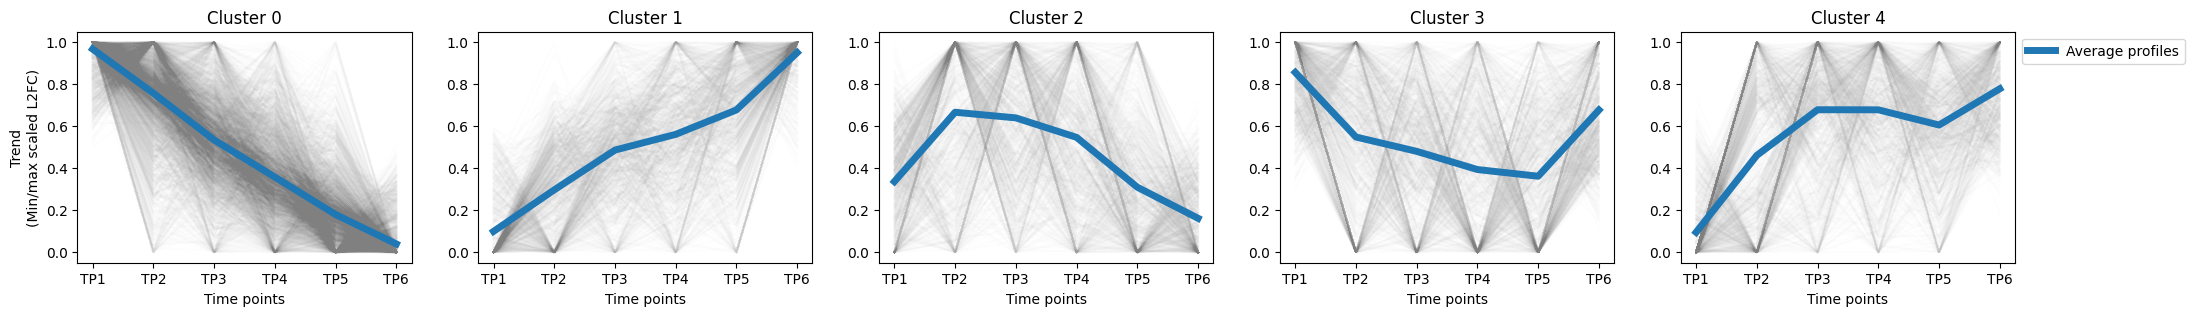

In [21]:
fig, axs = pl.subplots(1, K, figsize=(K*5, 3))
R = reps#reps_

for k in range(K):
    ax = axs[k]
    data = res[res['label']==k].drop('label', axis=1).values
    ax.plot(R.T[k], 
            label='Average profiles',
            # label='DTW Barycenter Average', 
            linewidth=5, zorder=10)
    for i in range(len(data)):
        ax.plot(data[i], alpha=0.01, color='grey')
    ax.set_title(f'Cluster {k}')
    ax.set_xlabel('Time points')
    if ax==axs[0]: ax.set_ylabel('Trend\n(Min/max scaled L2FC)')
    if ax==axs[-1]: ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    ax.set_xticks([0, 1, 2, 3, 4, 5], ['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6'])
pl.show()

In [22]:
# save scores and cluster assignments
scores.to_csv("../results/tables/timecourse_K5_clusters.csv")

In [23]:
# get best representing guides for each cluster
bests = {label: scores[scores['label']==label].sort_values('score', ascending=False).index for label in np.unique(labels)}

# Rank guides by their distance to the cluster representative
tops = pd.DataFrame(dict([ (k,pd.Series(v)) for k,v in bests.items() ]))
tops.columns = [f'Cluster_{x}' for x in tops.columns]
tops.to_csv("../results/tables/timecourse_K5_topgenes.csv")
tops

,Cluster_0,Cluster_1,Cluster_2,Cluster_3,Cluster_4
0,MRPL45_ENST00000312513_392,COX6B1_ENST00000246554_5,WWP1_ENST00000517970_3546,OR4S2_ENST00000312422_181,HOTAIRM1_ENST00000593300_237
1,DHX9_ENST00000367549_2741,CYP26B1_ENST00000461519_50,RHEB_ENST00000262187_273,TET2_ENST00000380013_2885,SNRNP27_ENST00000244227_1636
2,SNHG16_ENST00000493536_2093,CBR3-AS1_ENST00000427491_37,DCP2_ENST00000389063_189,DAD1_ENST00000250498_306,MYCNUT_ENST00000433810_983
3,DNMT1_ENST00000359526_5156,SHTN1_ENST00000355371_479,MBD1_ENST00000269468_768,TRAPPC8_ENST00000283351_5894,CHCHD7_ENST00000355315_195
4,SOD1_ENST00000270142_266,TMLHE_ENST00000369439_1052,MRPL45_ENST00000312513_394,PURPL_ENST00000512067_281,CENPN_ENST00000305850_2147
...,...,...,...,...,...
2747,NT_Control_rc_000996_NA,NaN,NaN,NaN,NaN
2748,TBCE_ENST00000406207_637,NaN,NaN,NaN,NaN
2749,DLEU1_ENST00000413510_249,NaN,NaN,NaN,NaN
2750,OR1D2_ENST00000331459_67,NaN,NaN,NaN,NaN


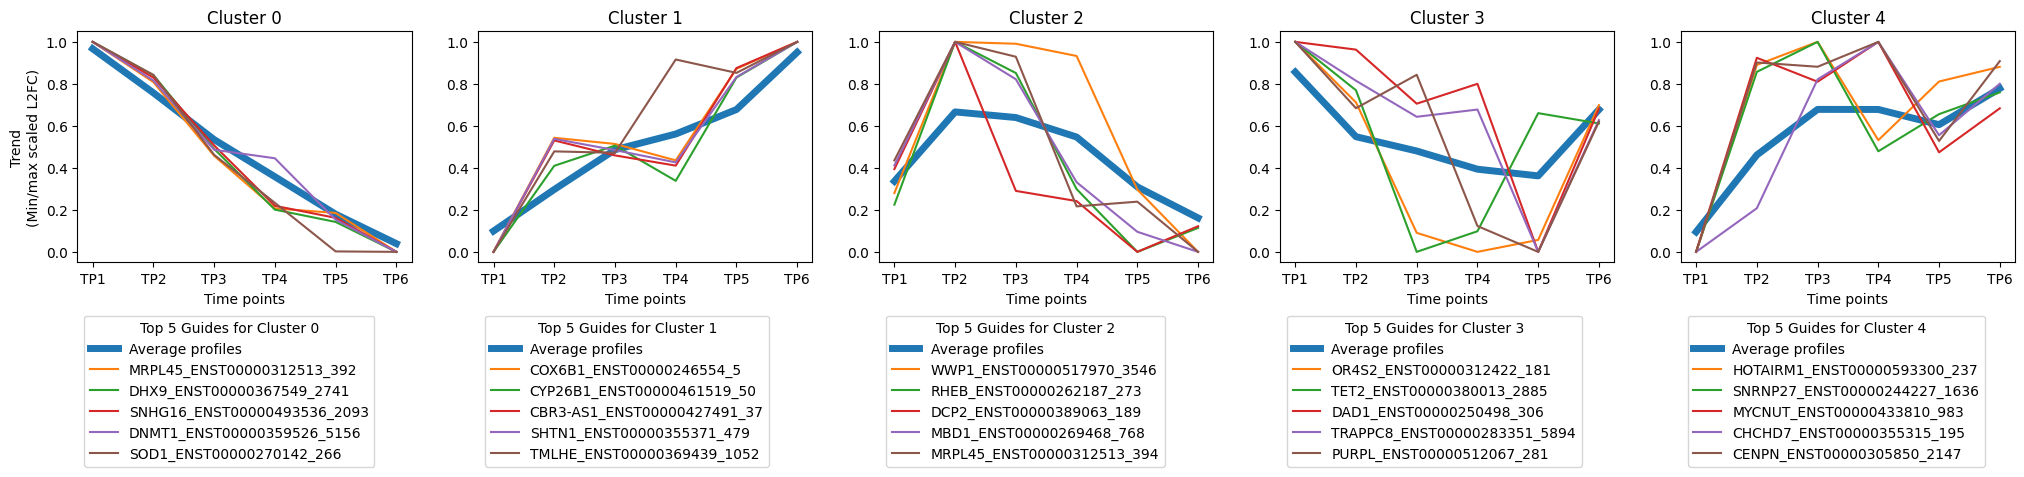

In [24]:
# Now plot those guides
fig, axs = pl.subplots(1, K, figsize=(K*5, 3))
R = reps#reps_

for k in range(K):
    ax = axs[k]
    data = res[res['label']==k].drop('label', axis=1)
    ax.plot(R.T[k], 
            label='Average profiles',
            linewidth=5, zorder=-1)
    best = tops[f'Cluster_{k}'].values[:5]
    for guide in best:
        ax.plot(data.loc[guide].values, alpha=1, label=guide)
    ax.set_title(f'Cluster {k}')
    ax.set_xlabel('Time points')
    if ax==axs[0]: ax.set_ylabel('Trend\n(Min/max scaled L2FC)')
    ax.legend(loc='upper left', bbox_to_anchor=(0, -0.2), title='Top 5 Guides for Cluster '+str(k))
    ax.set_xticks([0, 1, 2, 3, 4, 5], ['TP1', 'TP2', 'TP3', 'TP4', 'TP5', 'TP6'])
pl.show()

In [ ]:
# CRISPR scores distribution per cluster (we expect that the "Falling" cluster has the highest score)

In [30]:
res['Cas9_guide_score'] = df.loc[res.index, 'Guide_Score']

<Axes: xlabel='Guide_Score', ylabel='Count'>

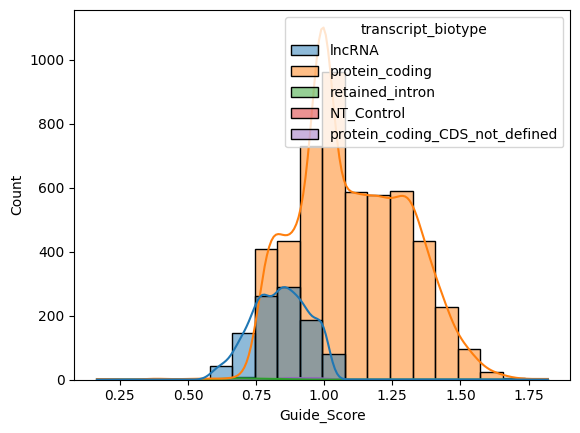

In [40]:
sns.histplot(data=df, x='Guide_Score', hue='transcript_biotype', kde=True, bins=20)

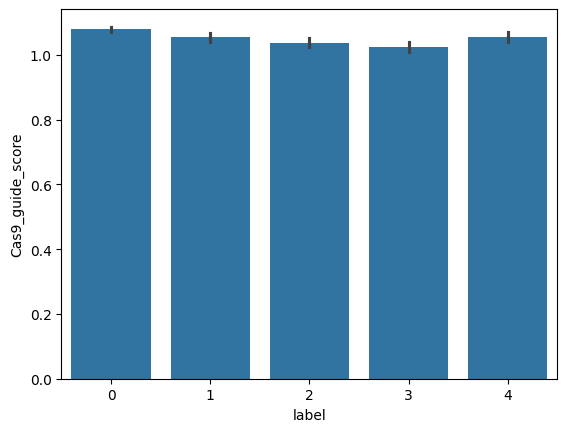

In [34]:
sns.barplot(x='label', y='Cas9_guide_score', data=res);